# 2.1. EDA general

Este cuaderno cubre los cuatro ítems de la sección 2.1 del enunciado: variable objetivo, calidad del
dataset, sesgos y desplazamientos de distribución, y partición. Cada análisis cierra con la decisión
de preprocesamiento, su impacto en la arquitectura y el riesgo de fuga.

**Datos usados.** Todo análisis que informa una decisión usa solo el entrenamiento (semanas objetivo
hasta el 2024-10-21). La prueba de 2025 entra en dos lugares, ambos exigidos por el enunciado: la
comparación de distribuciones entre particiones (sección 2.1.3, parte d) y la huella SHA-256 que la
congela (sección 2.1.4). Ninguna decisión de este cuaderno se tomó mirando la prueba. Además, 2025
ya se usó como prueba en el curso de Machine Learning (DECISIONES.md); eso se declara en el informe.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

sys.path.insert(0, str(Path.cwd()))
import comun as C  # noqa: E402

warnings.filterwarnings("ignore")
C.estilo()
pd.set_option("display.width", 150, "display.max_columns", 30, "display.precision", 4)

p = C.cargar()
tr = p[p["particion"] == "entrenamiento"].copy()
print(f"panel completo: {p.shape} | entrenamiento: {len(tr):,} filas")
R = {}

panel completo: (744921, 54) | entrenamiento: 622,244 filas


## 2.1.1 Variable objetivo

`y_reg = log1p(tasa_t1 / base8)`: logaritmo de uno más la razón entre el abastecimiento del corredor en
la semana t+1 (kg por día de encuesta) y su promedio de las 8 semanas previas. `y_reg` = ln 2 ≈ 0,693
significa que la semana t+1 igualó la base; `y_reg` = 0 significa que no hubo envíos. La interrupción
(`y_reg` < ln 1,5) es la versión binaria que se evalúa con AUC como métrica secundaria.

n : 622244
media : 0.6111
de : 0.4183
mediana : 0.6398
cuantiles : {0.01: 0.0, 0.05: 0.0, 0.25: 0.34321204437261155, 0.5: 0.6398078653735954, 0.75: 0.8368133460157148, 0.95: 1.3062491847430457, 0.99: 1.7983408696953391}
frac_cero : 0.1757
asimetria : 0.549
curtosis_exceso : 1.4613
asimetria_razon_sin_log : 411.0267
curtosis_razon_sin_log : 257422.9619
max : 7.1463
frac_mayor_ln2 : 0.4252
prevalencia_interrupcion : 0.2822
razon_desbalance : 2.5432
entropia_bits : 0.8585
consistencia_interrupcion : True
asimetria_sin_ceros : 1.2708
curtosis_sin_ceros : 4.3116


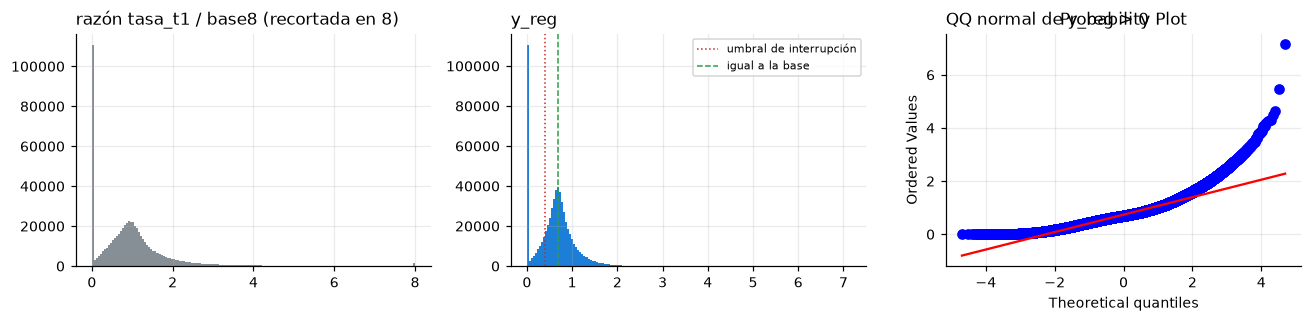

In [2]:
y = tr[C.OBJ]
ratio = np.expm1(y)
desc = {"n": int(len(y)), "media": y.mean(), "de": y.std(), "mediana": y.median(),
        "cuantiles": y.quantile([0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).to_dict(),
        "frac_cero": float((y == 0).mean()), "asimetria": float(stats.skew(y)), "curtosis_exceso": float(stats.kurtosis(y)),
        "asimetria_razon_sin_log": float(stats.skew(ratio)), "curtosis_razon_sin_log": float(stats.kurtosis(ratio)),
        "max": y.max(), "frac_mayor_ln2": float((y > np.log(2)).mean())}
prev = float(tr["interrupcion_t1"].mean())
desc |= {"prevalencia_interrupcion": prev, "razon_desbalance": (1 - prev) / prev,
         "entropia_bits": float(-(prev * np.log2(prev) + (1 - prev) * np.log2(1 - prev))),
         "consistencia_interrupcion": bool(((y < np.log(1.5)).astype(int) == tr["interrupcion_t1"]).all())}
y_pos = y[y > 0]
desc |= {"asimetria_sin_ceros": float(stats.skew(y_pos)), "curtosis_sin_ceros": float(stats.kurtosis(y_pos))}
for k, v in desc.items():
    print(k, ":", np.round(v, 4) if isinstance(v, float) else v)
R["objetivo"] = desc

fig, ax = plt.subplots(1, 3, figsize=(12, 3))
ax[0].hist(ratio.clip(upper=8), bins=160, color=C.GRIS)
ax[0].set_title("razón tasa_t1 / base8 (recortada en 8)", loc="left")
ax[1].hist(y, bins=160, color=C.AZUL)
ax[1].axvline(np.log(1.5), color=C.ROJO, ls=":", lw=1, label="umbral de interrupción")
ax[1].axvline(np.log(2), color=C.VERDE, ls="--", lw=1, label="igual a la base")
ax[1].set_title("y_reg", loc="left")
ax[1].legend(fontsize=7)
stats.probplot(y_pos, dist="norm", plot=ax[2])
ax[2].set_title("QQ normal de y_reg > 0", loc="left")
plt.tight_layout()
C.figura(fig, "general_objetivo")
plt.show()

`y_reg` tiene media 0,611 y mediana 0,640, ambas por debajo de ln 2 = 0,693: en la semana típica
el corredor envía algo menos que su base. El rasgo principal de la distribución es una masa puntual
en cero: el 17,6 % de las filas no tuvo envíos en t+1. Fuera de los ceros, la cola derecha es
moderada (asimetría 1,271 y curtosis en exceso 4,312 en `y_reg` > 0; con los ceros, 0,549 y 1,461).
El logaritmo es indispensable: en la escala de la razón, sin logaritmo, la asimetría es 411 y la
curtosis 257.423, porque hay razones de hasta 1.268 veces la base. La interrupción, que se evalúa
con AUC como métrica secundaria, tiene prevalencia de 28,2 % (razón 2,54 : 1, entropía de 0,859
bits), un desbalance moderado.

* **Preprocesamiento.** Se modela `y_reg` tal como está, sin una transformación Box–Cox adicional.
  No hay remuestreo ni ponderación: el problema es de regresión, y el desbalance de la interrupción
  no afecta al AUC.
* **Arquitectura.** Una salida escalar lineal. Con un 17,6 % de ceros, la pérdida L1 es más adecuada
  que el MSE: estima la mediana condicional, que puede ser cero. Un modelo de dos partes
  (probabilidad de cero y magnitud) queda como alternativa para el Entregable 2, no para los modelos
  base.
* **Fuga.** `tasa_t1`, `ratio_t1` e `interrupcion_t1` son funciones del objetivo y no pueden entrar
  como variables.

## 2.1.2 Calidad del dataset

### a) Valores faltantes y su mecanismo

Hay dos tipos de faltantes. El primero son las celdas vacías en columnas de las filas existentes. El
segundo son las corredor-semanas ausentes del panel, que se analizan en el cuaderno 03 (sección B.5)
porque determinan la política de la ventana. Aquí se tratan las celdas vacías. Para cada columna con
faltantes se compara la distribución de `y_reg` con y sin el dato, y se evalúa si la ausencia se
puede predecir con variables observadas (evidencia de MAR) mediante una regresión logística.

In [3]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

falt = tr.isna().sum()
falt = falt[falt > 0].sort_values(ascending=False)
print("columnas con faltantes en el entrenamiento:")
print(pd.DataFrame({"faltantes": falt, "fraccion": falt / len(tr)}).to_string())
explic = ["log_base8", "activas8", "activas26", "cv8", "dist_km", "antig_sem", "ratio_t", "n_envios8"]
mec = {}
for col in falt.index:
    m = tr[col].isna()
    fila = {"faltantes": int(m.sum()), "fraccion": float(m.mean()),
            "y_media_con_dato": float(tr.loc[~m, C.OBJ].mean()), "y_media_sin_dato": float(tr.loc[m, C.OBJ].mean()),
            "p_mann_whitney_y": float(stats.mannwhitneyu(tr.loc[m, C.OBJ], tr.loc[~m, C.OBJ]).pvalue)}
    X = tr[explic].fillna(0).to_numpy()
    idx = np.random.default_rng(C.SEMILLA).choice(len(tr), min(len(tr), 200_000), replace=False)
    pr = cross_val_predict(make_pipeline(StandardScaler(), LogisticRegression(max_iter=500)),
                           X[idx], m.to_numpy()[idx], cv=3, method="predict_proba")[:, 1]
    fila["auc_logistica_mar"] = float(roc_auc_score(m.to_numpy()[idx], pr))
    mec[col] = fila
mec = pd.DataFrame(mec).T
print(mec.round(4).to_string())
# Causa estructural de cada faltante
n_mpio = tr.groupby(["semana", "cod_mpio"])["mercado"].transform("size")
print("frac_caida_mpio_t faltante <=> el municipio tiene un solo corredor en la semana:",
      bool((tr["frac_caida_mpio_t"].isna() == (n_mpio == 1)).all()))
orden = tr.sort_values(C.CLAVE + ["semana"])
prev_sem = orden.groupby(C.CLAVE)["semana"].shift(1)
print("ratio_t_1 faltante en filas cuya semana anterior no está en el panel:",
      f"{orden.loc[orden['ratio_t_1'].isna(), 'semana'].sub(prev_sem[orden['ratio_t_1'].isna()]).dt.days.ne(7).mean():.3f}")
R["faltantes"] = mec.reset_index().rename(columns={"index": "columna"}).to_dict("records")

columnas con faltantes en el entrenamiento:
                   faltantes  fraccion
frac_caida_mpio_t      97840    0.1572
frac_caida_vec_t        6144    0.0099
tasa_int_vec26          2190    0.0035
ratio_t_1                192    0.0003


                   faltantes  fraccion  y_media_con_dato  y_media_sin_dato  p_mann_whitney_y  auc_logistica_mar
frac_caida_mpio_t    97840.0    0.1572            0.6129            0.6019               0.0             0.7541
frac_caida_vec_t      6144.0    0.0099            0.6116            0.5662               0.0             0.7121
tasa_int_vec26        2190.0    0.0035            0.6114            0.5356               0.0             0.8524
ratio_t_1              192.0    0.0003            0.6112            0.4907               0.0             0.8595
frac_caida_mpio_t faltante <=> el municipio tiene un solo corredor en la semana: True
ratio_t_1 faltante en filas cuya semana anterior no está en el panel: 1.000


### b) Datos corruptos, inconsistentes o fuera de rango

Cada regla verifica una propiedad que se sigue de la construcción del panel o del dominio físico. Se
reporta el número de filas del entrenamiento que la violan.

In [4]:
sh = [c for c in tr.columns if c.startswith("sh_")]
reglas = {
    "y_reg >= 0": (tr[C.OBJ] < 0),
    "tasa_t >= 0 y tasa_t1 >= 0": (tr["tasa_t"] < 0) | (tr["tasa_t1"] < 0),
    "base8 > 0": ~(tr["base8"] > 0),
    "y_reg = log1p(tasa_t1 / base8)": ~np.isclose(tr[C.OBJ], np.log1p(tr["tasa_t1"] / tr["base8"])),
    "ratio_t = tasa_t / base8": ~np.isclose(tr["ratio_t"], tr["tasa_t"] / tr["base8"]),
    "semana_t1 = semana + 7 días": (tr["semana_t1"] - tr["semana"]).dt.days != 7,
    "semana es lunes": tr["semana"].dt.dayofweek != 0,
    "activas8 entre 4 y 8": ~tr["activas8"].between(4, 8),
    "activas26 entre 0 y 1": ~tr["activas26"].between(0, 1),
    "participaciones sh_* entre 0 y 1": ~tr[sh].fillna(0).apply(lambda s: s.between(0, 1)).all(axis=1),
    "participaciones suman 1": ~np.isclose(tr[sh].sum(axis=1), 1, atol=1e-6),
    "dist_km >= 0": tr["dist_km"] < 0,
    "local = 1 sii dist_km = 0": (tr["local"] == 1) != (tr["cod_mpio"] == tr["cod_mpio_mercado"]),
    "coordenadas dentro de Colombia": ~(tr["lat_o"].between(-4.3, 13.5) & tr["lon_o"].between(-82, -66.8)),
    "festivos_t1 entre 0 y 7": ~tr["festivos_t1"].between(0, 7),
    "interrupcion_t1 = [y_reg < ln 1,5]": (tr[C.OBJ] < np.log(1.5)).astype(int) != tr["interrupcion_t1"],
}
tab_r = pd.Series({k: int(v.sum()) for k, v in reglas.items()}, name="filas que violan")
print(tab_r.to_string())
print("máximo de y_reg:", round(tr[C.OBJ].max(), 3), f"(razón {np.expm1(tr[C.OBJ].max()):.1f} veces la base)")
R["reglas"] = tab_r.to_dict()

y_reg >= 0                            0
tasa_t >= 0 y tasa_t1 >= 0            0
base8 > 0                             0
y_reg = log1p(tasa_t1 / base8)        0
ratio_t = tasa_t / base8              0
semana_t1 = semana + 7 días           0
semana es lunes                       0
activas8 entre 4 y 8                  0
activas26 entre 0 y 1                 0
participaciones sh_* entre 0 y 1      0
participaciones suman 1               0
dist_km >= 0                          0
local = 1 sii dist_km = 0             0
coordenadas dentro de Colombia        0
festivos_t1 entre 0 y 7               0
interrupcion_t1 = [y_reg < ln 1,5]    0
máximo de y_reg: 7.146 (razón 1268.5 veces la base)


### c) Duplicados exactos y casi duplicados

Un duplicado exacto sería una corredor-semana repetida. Un casi duplicado sería dos corredores con la
misma serie: el mismo envío registrado dos veces en mercados distintos, o un municipio de origen mal
codificado. Para detectarlos se comparan las series `tasa_t` de cada par de corredores en las semanas
que comparten, siempre que compartan al menos 26.

In [5]:
dup_clave = int(tr.duplicated(C.CLAVE + ["semana"]).sum())
dup_fila = int(tr.drop(columns=["fila"]).duplicated().sum())
T, corredores, semanas = C.matriz_tasa(tr, hasta=C.FIN_TRAIN)
largas = np.flatnonzero((~np.isnan(T)).sum(axis=1) >= 26)
# Huella de cada serie: valores redondeados en las semanas observadas
firmas = {}
for i in largas:
    v = T[i]
    ok = ~np.isnan(v) & (v > 0)
    if ok.sum() >= 26:
        firmas.setdefault(hash((tuple(np.flatnonzero(ok)), tuple(np.round(v[ok], 3)))), []).append(i)
grupos_dup = [g for g in firmas.values() if len(g) > 1]
# Casi duplicados: correlación > 0,999 entre corredores del mismo municipio de origen y distinto mercado
casi = []
mpios = corredores.get_level_values(1)
for mp in pd.unique(mpios[largas]):
    ii = [i for i in largas if mpios[i] == mp]
    for a in range(len(ii)):
        for b in range(a + 1, len(ii)):
            x, z = T[ii[a]], T[ii[b]]
            ok = ~np.isnan(x) & ~np.isnan(z)
            if ok.sum() >= 26 and x[ok].std() > 0 and z[ok].std() > 0:
                r = np.corrcoef(x[ok], z[ok])[0, 1]
                if r > 0.999:
                    casi.append((corredores[ii[a]], corredores[ii[b]], int(ok.sum()), r))
print(f"corredor-semanas repetidas: {dup_clave} | filas completas repetidas: {dup_fila}")
print(f"series idénticas (>= 26 semanas positivas): {sum(len(g) for g in grupos_dup)} corredores en {len(grupos_dup)} grupos")
print(f"pares del mismo municipio con correlación > 0,999 en >= 26 semanas comunes: {len(casi)}")
for c_ in casi[:10]:
    print("  ", c_)
R["duplicados"] = {"clave_repetida": dup_clave, "fila_repetida": dup_fila,
                   "grupos_series_identicas": len(grupos_dup), "pares_casi_duplicados": len(casi),
                   "detalle_casi": [[list(a), list(b), n, r] for a, b, n, r in casi]}

corredor-semanas repetidas: 0 | filas completas repetidas: 0
series idénticas (>= 26 semanas positivas): 0 corredores en 0 grupos
pares del mismo municipio con correlación > 0,999 en >= 26 semanas comunes: 0


### d) Ruido de la variable objetivo

El objetivo no lo asigna un anotador. Sale de una medición: los encuestadores de SIPSA registran las
cargas que entran a cada central mayorista, y la tasa se calcula en kg por día encuestado. La fuente
de ruido esperada es que la semana t+1 tenga menos días encuestados de lo normal, porque con pocos
días un envío ausente o concentrado pesa más. El panel no incluye los días encuestados; el script
auxiliar los obtiene de los envíos de DANE (`aux_cobertura_envios.json`).

In [6]:
import json

aux = json.loads((C.RES / "aux_cobertura_envios.json").read_text())
pd_dias = pd.DataFrame(aux["por_dias_encuestados_t1"]).set_index("dias_t1")
pd_dias["frac_filas"] = pd.Series({int(float(k)): v for k, v in aux["frac_filas_dias_t1"].items()})
print(pd_dias.round(3).to_string())
pocos = pd_dias.loc[pd_dias.index <= 3, "filas"].sum() / pd_dias["filas"].sum()
print(f"filas con 3 o menos días encuestados en t+1: {pocos:.4f}")
R["ruido"] = {"frac_filas_3_dias_o_menos": float(pocos)}

          filas  y_media   y_de  frac_y_cero  frac_interrupcion  frac_filas
dias_t1                                                                    
1           145    0.222  0.446        0.731              0.800       0.000
2          1113    0.571  0.507        0.303              0.393       0.002
3          6679    0.584  0.470        0.264              0.346       0.011
4         40602    0.602  0.434        0.204              0.302       0.065
5        123381    0.604  0.434        0.198              0.301       0.198
6        251810    0.607  0.419        0.179              0.288       0.405
7        198514    0.624  0.400        0.147              0.256       0.319
filas con 3 o menos días encuestados en t+1: 0.0128


**Faltantes.** Cuatro columnas tienen celdas vacías, todas por razones estructurales:

* `frac_caida_mpio_t` (15,7 %) falta exactamente en las filas cuyo municipio tiene un solo corredor
  esa semana, porque no hay "otros corredores" con los cuales calcularla.
* `ratio_t_1` (0,03 %) falta en todas las filas cuya semana anterior no está en el panel.
* `frac_caida_vec_t` (1,0 %) y `tasa_int_vec26` (0,35 %) faltan cuando ninguno de los 8 municipios
  vecinos tiene corredores activos.

Una regresión logística predice la ausencia con las variables observadas (AUC entre 0,71 y 0,86), y
el objetivo difiere entre filas con y sin dato (`y_reg` medio de 0,491 frente a 0,611 en
`ratio_t_1`). Es decir, la ausencia es MAR respecto de variables observadas y además informativa.

**Rangos e inconsistencias.** Las 16 reglas de construcción y de dominio se cumplen en todas las
filas. El máximo de `y_reg` (7,146, una razón de 1.268) es extremo, pero no es un error: sale de una
base muy pequeña (ver B.6 en el cuaderno 03).

**Duplicados.** No hay corredor-semanas repetidas, ni series idénticas entre corredores, ni pares
del mismo municipio con correlación mayor que 0,999. Que un mismo corredor aparezca en el
entrenamiento y en la prueba no es fuga: la partición es temporal y el objetivo es pronosticar esos
mismos corredores en el futuro.

**Ruido del objetivo.** Las filas cuya semana t+1 tuvo 3 días encuestados o menos son el 1,28 %, y
tienen muchos más ceros: 73,1 % con un día, 30,3 % con dos y 26,4 % con tres, frente a 14,7 % con
siete. Dividir por los días encuestados no corrige el efecto. Una parte de los ceros y de las
interrupciones es, por lo tanto, un artefacto de una encuesta incompleta, y ese ruido pone un piso al
MAE que puede alcanzar cualquier modelo.

* **Preprocesamiento.** Cada covariable con faltantes se imputa con la mediana de las filas de ajuste
  de cada origen, más una columna indicadora de ausencia (cuatro indicadores). Las filas con pocos
  días encuestados se conservan, porque en t no se sabe cuántos días se encuestarán en t+1. Como
  análisis de sensibilidad se puede reportar el MAE sin esas filas.
* **Arquitectura.** Los indicadores entran como covariables en las tres redes.
* **Fuga.** Las medianas de imputación se calculan solo con las filas de ajuste. Los días encuestados
  en t+1 son información futura y no pueden ser una variable de entrada.

## 2.1.3 Sesgos y desplazamientos de distribución

### a) Sesgos de representación

In [7]:
rep_m = tr.groupby("mercado").agg(filas=(C.OBJ, "size"), corredores=("cod_mpio", "nunique"), y_media=(C.OBJ, "mean"))
rep_m["frac_filas"] = rep_m["filas"] / len(tr)
rep_m = rep_m.sort_values("filas", ascending=False)
print(rep_m.head(8).round(3).to_string())
print(f"mercados: {len(rep_m)} | los 5 con más filas suman {rep_m['frac_filas'].head(5).sum():.3f} | "
      f"Bogotá (Corabastos) suma {rep_m.loc[rep_m.index.str.startswith('Bogotá'), 'frac_filas'].sum():.3f}")
rep_g = tr.groupby("grupo_dom").agg(filas=(C.OBJ, "size"), y_media=(C.OBJ, "mean"),
                                    frac_cero=(C.OBJ, lambda s: float((s == 0).mean())))
rep_g["frac_filas"] = rep_g["filas"] / len(tr)
print(rep_g.sort_values("filas", ascending=False).round(3).to_string())
rep_d = tr["depto_origen"].value_counts(normalize=True)
print(f"departamentos de origen: {len(rep_d)} | los 3 primeros: {rep_d.head(3).round(3).to_dict()}")
print("filas con origen en municipio PDET:", round(tr["pdet_origen"].mean(), 3), "| origen local:", round(tr["local"].mean(), 3))
# ¿La calidad de un pronóstico ingenuo cambia por grupo? (MAE de la mediana global del entrenamiento)
med = tr[C.OBJ].median()
mae_m = tr.assign(e=(tr[C.OBJ] - med).abs()).groupby("mercado")["e"].mean()
print(f"MAE de la mediana global por mercado: mínimo {mae_m.min():.3f}, máximo {mae_m.max():.3f}")
R["representacion"] = {"mercados": rep_m.reset_index().to_dict("records"),
                       "grupos": rep_g.reset_index().to_dict("records"),
                       "frac_top5_mercados": float(rep_m["frac_filas"].head(5).sum()),
                       "deptos_top3": rep_d.head(3).to_dict(), "n_deptos": int(len(rep_d)),
                       "frac_pdet": float(tr["pdet_origen"].mean()), "frac_local": float(tr["local"].mean()),
                       "mae_mediana_por_mercado": [float(mae_m.min()), float(mae_m.max())]}

                                              filas  corredores  y_media  frac_filas
mercado                                                                             
Bogotá, D.C., Corabastos                      92238         462    0.623       0.148
Medellín, Central Mayorista de Antioquia      55604         352    0.626       0.089
Bucaramanga, Centroabastos                    41897         273    0.619       0.067
Medellín, Plaza Minorista "José María Villa"  35518         236    0.614       0.057
Barranquilla, Barranquillita                  32918         204    0.613       0.053
Cali, Cavasa                                  28706         190    0.619       0.046
Cartagena, Bazurto                            24519         187    0.600       0.039
Cúcuta, Cenabastos                            24383         154    0.634       0.039
mercados: 32 | los 5 con más filas suman 0.415 | Bogotá (Corabastos) suma 0.216
             filas  y_media  frac_cero  frac_filas
grupo_dom          

### b) Sesgos temporales y espaciales

Para el componente temporal se calculan la media de `y_reg`, la fracción de ceros, las filas y los
corredores activos por año. Para el espacial, el I de Moran global de la media de `y_reg` por
municipio de origen (municipios con al menos 52 semanas en riesgo). Los pesos son binarios con los 8
vecinos más cercanos, estandarizados por fila: la misma vecindad que usan las variables espaciales de
`datos_ml.py`.

In [8]:
anual = tr.groupby("anio_t1").agg(filas=(C.OBJ, "size"), corredores=("cod_mpio", lambda s: tr.loc[s.index, C.CLAVE].drop_duplicates().shape[0]),
                                  y_media=(C.OBJ, "mean"), frac_cero=(C.OBJ, lambda s: float((s == 0).mean())),
                                  interrupcion=("interrupcion_t1", "mean"))
print(anual.round(3).to_string())
kw = stats.kruskal(*[g[C.OBJ].to_numpy() for _, g in tr.groupby("anio_t1")])
print(f"Kruskal-Wallis de y_reg entre años: H = {kw.statistic:.1f}, p = {kw.pvalue:.2e}; "
      f"épsilon² = {(kw.statistic - anual.shape[0] + 1) / (len(tr) - anual.shape[0]):.4f}")

nac_sem = tr.groupby("semana")["frac_caida_nacional_t"].first().sort_values(ascending=False)
print("semanas t con mayor fracción nacional de corredores en caída:", nac_sem.head(3).round(3).to_dict())

import datos_ml  # noqa: E402

mun = tr.groupby("cod_mpio").agg(y=(C.OBJ, "mean"), filas=(C.OBJ, "size"), lat=("lat_o", "first"), lon=("lon_o", "first"))
mun = mun[mun["filas"] >= 52]
vec = datos_ml.vecinos_knn(mun["lat"].to_numpy(), mun["lon"].to_numpy(), 8)
z = mun["y"].to_numpy() - mun["y"].mean()
I = float((z @ z[vec].mean(axis=1)) / (z @ z))
rng = np.random.default_rng(C.SEMILLA)
sim = np.array([(zp @ zp[vec].mean(axis=1)) / (zp @ zp) for zp in (rng.permutation(z) for _ in range(999))])
p_I = (np.sum(sim >= I) + 1) / 1000
print(f"I de Moran de la media de y_reg por municipio de origen: I = {I:.3f} (E[I] = {-1 / (len(mun) - 1):.4f}), "
      f"z = {(I - sim.mean()) / sim.std(ddof=1):.1f}, p de permutación = {p_I:.3f}, municipios = {len(mun)}")
R["temporal"] = {"anual": anual.reset_index().to_dict("records"), "kruskal_H": kw.statistic, "kruskal_p": kw.pvalue,
                 "semanas_mayor_caida_nacional": {str(k.date()): float(v) for k, v in nac_sem.head(3).items()},
                 "epsilon2": (kw.statistic - anual.shape[0] + 1) / (len(tr) - anual.shape[0])}
R["espacial"] = {"moran_I": I, "E_I": -1 / (len(mun) - 1), "z": float((I - sim.mean()) / sim.std(ddof=1)),
                 "p_perm": float(p_I), "municipios": int(len(mun))}

         filas  corredores  y_media  frac_cero  interrupcion
anio_t1                                                     
2018     83578        2705    0.610      0.173         0.282
2019     90450        2722    0.609      0.175         0.281
2020     89438        2712    0.616      0.175         0.281
2021     90295        2788    0.606      0.186         0.297
2022     92011        2723    0.605      0.180         0.288
2023     94334        2852    0.617      0.174         0.274
2024     82138        2767    0.615      0.166         0.270
Kruskal-Wallis de y_reg entre años: H = 106.4, p = 1.14e-20; épsilon² = 0.0002
semanas t con mayor fracción nacional de corredores en caída: {Timestamp('2021-05-03 00:00:00'): 0.495, Timestamp('2018-12-31 00:00:00'): 0.366, Timestamp('2019-12-30 00:00:00'): 0.365}
I de Moran de la media de y_reg por municipio de origen: I = 0.185 (E[I] = -0.0013), z = 11.2, p de permutación = 0.001, municipios = 779


### c) Correlaciones espurias y atributos con fuga

Hay dos preguntas. La primera: ¿alguna columna del panel está calculada con información de t+1? Esas
columnas no pueden entrar al modelo. La segunda: ¿alguna variable sin relación causal plausible con
el abastecimiento de la semana siguiente se asocia con `y_reg`? Ese sería un posible atajo
(*shortcut*). Se mide la información mutua de cada covariable numérica con `y_reg` en una muestra
de 100.000 filas, junto con la correlación de Spearman.

In [9]:
from sklearn.feature_selection import mutual_info_regression

fuga = {"tasa_t1": "numerador del objetivo", "interrupcion_t1": "umbral aplicado al objetivo",
        "ratio_t1": "objetivo sin logaritmo", "y_reg": "objetivo", "fila": "índice ordenado por semana objetivo",
        "anio_t1": "año de la semana objetivo (se conoce de antemano: no es fuga, pero codifica el tiempo absoluto)",
        "mes_t1": "mes de la semana objetivo (idem)"}
print("columnas que no pueden entrar al modelo o que exigen cuidado:")
for k, v in fuga.items():
    print(f"  {k}: {v}")
num = [c for c in tr.select_dtypes("number").columns
       if c not in {"tasa_t1", "interrupcion_t1", "ratio_t1", C.OBJ, "fila", "anio_t1", "lat_m", "lon_m"}]
mues = tr.sample(100_000, random_state=C.SEMILLA)
Xm = mues[num].fillna(mues[num].median())
mi = mutual_info_regression(Xm, mues[C.OBJ], random_state=C.SEMILLA, n_neighbors=3)
sp = [stats.spearmanr(Xm[c], mues[C.OBJ]).statistic for c in num]
tab_mi = pd.DataFrame({"info_mutua": mi, "spearman": sp}, index=num).sort_values("info_mutua", ascending=False)
print(tab_mi.round(4).to_string())
R["asociacion"] = tab_mi.reset_index().rename(columns={"index": "variable"}).to_dict("records")

columnas que no pueden entrar al modelo o que exigen cuidado:
  tasa_t1: numerador del objetivo
  interrupcion_t1: umbral aplicado al objetivo
  ratio_t1: objetivo sin logaritmo
  y_reg: objetivo
  fila: índice ordenado por semana objetivo
  anio_t1: año de la semana objetivo (se conoce de antemano: no es fuga, pero codifica el tiempo absoluto)
  mes_t1: mes de la semana objetivo (idem)


                       info_mutua  spearman
n_envios8                  0.2407    0.1751
cv8                        0.2348   -0.1774
log_base8                  0.2180    0.1306
activas26                  0.2064    0.2002
activas8                   0.2041    0.1736
n_alimentos8               0.1818    0.1640
base8                      0.1786    0.1306
tasa_t                     0.1627    0.1937
ratio_t                    0.1593    0.1710
ratio_t_1                  0.1468    0.1344
dist_km                    0.1037   -0.0725
pend8_rel                  0.0909    0.1637
tasa_int_mpio26            0.0696   -0.1055
lat_o                      0.0580    0.0045
lon_o                      0.0541   -0.0027
sh_verduras                0.0497    0.0715
sh_tuberculos              0.0477    0.0603
sh_frutas                  0.0425    0.0030
sh_granos                  0.0153    0.0027
sh_lacteos                 0.0140    0.0227
mismo_depto                0.0136    0.0615
sh_procesados              0.012

### d) Desplazamiento de covariables entre particiones

Se hacen dos comparaciones con la misma prueba: un clasificador adversarial (*gradient boosting* con
histogramas, AUC con validación cruzada de 5 pliegues) que intenta distinguir de qué bloque viene
cada fila, más el índice de estabilidad poblacional (PSI) por variable.

1. **Dentro del entrenamiento:** primeras semanas frente a las últimas 52. Es lo que enfrentará cada
   origen de la validación de origen móvil.
2. **Entrenamiento frente a prueba de 2025.** Es el único análisis de este cuaderno que lee la prueba,
   y se hace porque el enunciado lo exige. No cambia ninguna decisión de preprocesamiento.

Algunas variables separan los bloques por construcción, no porque cambie la relación con el
objetivo. `antig_sem` (semanas desde la primera carga del corredor) crece con el calendario. Las
variables que valen lo mismo para todas las filas de una semana (`frac_caida_nacional_t`,
`sem_sin`, `sem_cos`, `festivos_t1`) o de una semana y mercado (`frac_caida_mercado_t`) identifican
la semana, y cualquier clasificador puede reconocer de qué bloque es. Por eso el AUC se reporta con
tres conjuntos: todas las variables, sin `antig_sem` ni `activas26`, y además sin las variables de
nivel semana. El tercero es el que mide un desplazamiento de las covariables propias de cada
corredor.

In [10]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score

cov = ["ratio_t", "ratio_t_1", "log_base8", "cv8", "pend8_rel", "activas8", "activas26", "n_envios8", "n_alimentos8",
       "antig_sem", "frac_caida_mercado_t", "frac_caida_nacional_t", "frac_caida_mpio_t", "frac_caida_vec_t",
       "tasa_int_vec26", "tasa_int_mpio26", "dist_km", "festivos_t1", "sem_sin", "sem_cos"] + sh
sin_tiempo = [c for c in cov if c not in ("antig_sem", "activas26")]
nivel_semana = ["frac_caida_nacional_t", "frac_caida_mercado_t", "sem_sin", "sem_cos", "festivos_t1"]
corredor = [c for c in sin_tiempo if c not in nivel_semana]


def adversarial(a, b, cols, n=60_000):
    xa = a.sample(min(n, len(a)), random_state=C.SEMILLA)[cols]
    xb = b.sample(min(n, len(b)), random_state=C.SEMILLA)[cols]
    X = pd.concat([xa, xb])
    yb = np.r_[np.zeros(len(xa)), np.ones(len(xb))]
    cv = StratifiedKFold(5, shuffle=True, random_state=C.SEMILLA)
    return float(cross_val_score(HistGradientBoostingClassifier(random_state=C.SEMILLA), X, yb, cv=cv, scoring="roc_auc").mean())


ult = tr["semana_t1"].max() - pd.Timedelta(weeks=52)
tr_ini, tr_fin = tr[tr["semana_t1"] <= ult - pd.Timedelta(weeks=C.HUECO)], tr[tr["semana_t1"] > ult]
te = p[p["particion"] == "prueba"]
desp = {}
for nombre, (a, b) in {"entrenamiento_inicio_vs_ultimas52": (tr_ini, tr_fin), "entrenamiento_vs_prueba2025": (tr, te)}.items():
    psi = pd.Series({c: C.psi(a[c], b[c]) for c in cov}).sort_values(ascending=False)
    desp[nombre] = {"auc_todas": adversarial(a, b, cov), "auc_sin_tiempo": adversarial(a, b, sin_tiempo),
                    "auc_corredor": adversarial(a, b, corredor),
                    "psi": psi.to_dict(), "psi_mayor_0_2": psi[psi > 0.2].index.tolist(),
                    "psi_y_reg": C.psi(a[C.OBJ], b[C.OBJ]),
                    "media_frac_caida_nacional": [float(a["frac_caida_nacional_t"].mean()), float(b["frac_caida_nacional_t"].mean())]}
    d = desp[nombre]
    print(f"{nombre}: AUC adversarial con todas {d['auc_todas']:.3f} | sin antig_sem ni activas26 {d['auc_sin_tiempo']:.3f} | "
          f"solo variables del corredor {d['auc_corredor']:.3f} | PSI de y_reg {d['psi_y_reg']:.3f}")
    print("   PSI > 0,10:", psi[psi > 0.1].round(3).to_dict())
    print("   media de frac_caida_nacional_t en cada bloque:", np.round(d["media_frac_caida_nacional"], 3))
print("frac_caida_nacional_t por año (entrenamiento):",
      tr.groupby("anio_t1")["frac_caida_nacional_t"].agg(["mean", "min", "max"]).round(3).to_dict("index"))
R["desplazamiento"] = desp

entrenamiento_inicio_vs_ultimas52: AUC adversarial con todas 1.000 | sin antig_sem ni activas26 1.000 | solo variables del corredor 0.727 | PSI de y_reg 0.002
   PSI > 0,10: {'antig_sem': 4.026, 'frac_caida_nacional_t': 3.803}
   media de frac_caida_nacional_t en cada bloque: [0.241 0.227]


entrenamiento_vs_prueba2025: AUC adversarial con todas 1.000 | sin antig_sem ni activas26 1.000 | solo variables del corredor 0.717 | PSI de y_reg 0.004
   PSI > 0,10: {'antig_sem': 4.12, 'frac_caida_nacional_t': 2.116}
   media de frac_caida_nacional_t en cada bloque: [0.238 0.222]
frac_caida_nacional_t por año (entrenamiento): {2018: {'mean': 0.234, 'min': 0.085, 'max': 0.346}, 2019: {'mean': 0.237, 'min': 0.198, 'max': 0.366}, 2020: {'mean': 0.239, 'min': 0.188, 'max': 0.365}, 2021: {'mean': 0.252, 'min': 0.204, 'max': 0.495}, 2022: {'mean': 0.244, 'min': 0.202, 'max': 0.317}, 2023: {'mean': 0.231, 'min': 0.195, 'max': 0.356}, 2024: {'mean': 0.23, 'min': 0.196, 'max': 0.362}}


**Representación.** Los 5 mercados con más filas suman el 41,5 % del entrenamiento. Corabastos aporta
el 14,8 % y los mercados de Bogotá en conjunto el 21,6 %. Por grupo dominante, las frutas son el
34,6 % de las filas y los pescados el 2,3 %, con un 33,3 % de ceros, casi el doble del 17,6 % general.
Cundinamarca, Antioquia y Boyacá concentran el 33,5 % de los orígenes. El MAE de la mediana global
va de 0,249 a 0,457 según el mercado: el error no será parejo, y la evaluación debe reportarlo por
mercado y por grupo.

**Sesgo temporal.** No hay cambio de régimen en el nivel del objetivo. La media anual de `y_reg` va
de 0,605 a 0,617 y la fracción de ceros de 16,6 % a 18,6 %. Kruskal–Wallis detecta diferencias entre
años (p = 1,1 × 10⁻²⁰) solo por el tamaño de la muestra: el efecto es nulo en la práctica
(ε² = 0,0002). El año con más ceros es 2021, y la semana con más corredores en caída del
entrenamiento es la que empieza el 2021-05-03 (49,5 %), que coincide con el paro nacional iniciado
a finales de abril de 2021. El panel por sí solo no permite atribuirle la causa.

**Sesgo espacial.** El nivel de `y_reg` se agrupa en el espacio: el I de Moran de la media por
municipio de origen es 0,185 (z = 11,2; p de permutación = 0,001; 779 municipios).

**Atajos y fuga.** Ninguna variable sin una relación plausible con el abastecimiento futuro tiene
información mutua apreciable: `antig_sem` tiene 0,000 y `festivos_t1` 0,0006. Las más informativas
describen la regularidad del corredor (`n_envios8` 0,241, `cv8` 0,235, `log_base8` 0,218). La latitud
y la longitud tienen información mutua de 0,058 y 0,054 con Spearman casi nulo: es un efecto
geográfico no lineal, coherente con el I de Moran. Es legítimo, pero puede funcionar como un
identificador del corredor. Las columnas derivadas del objetivo quedan listadas como prohibidas.

**Desplazamiento entre particiones.** Con todas las variables, el clasificador adversarial separa
perfectamente los bloques (AUC = 1,000), en las dos comparaciones. La razón son las variables de
nivel semana, que identifican el calendario. Con solo las variables propias del corredor, el AUC
baja a 0,727 dentro del entrenamiento y a 0,717 entre el entrenamiento y la prueba. El objetivo
apenas se mueve (PSI de `y_reg` de 0,002 y 0,004). Los PSI mayores que 0,1 son `antig_sem` (4,0),
que crece con el calendario, y `frac_caida_nacional_t` (3,8 y 2,1). Este último es un artefacto: la
variable toma un solo valor por semana, y con 52 valores los cortes por cuantiles dejan
compartimentos vacíos. Sus medias son casi iguales (0,241 frente a 0,227).

* **Preprocesamiento.** `antig_sem` no debe entrar sin recorte, porque en la prueba toma valores que
  nunca vio el ajuste. Se recomienda excluirla o recortarla al rango del ajuste de cada origen.
  `anio_t1` y `mes_t1` no entran; la estacionalidad va por `sem_sin` y `sem_cos`.
* **Arquitectura.** Los *embeddings* de municipio y de mercado, junto con las variables espaciales,
  recogen la agrupación espacial del nivel. No se particiona por bloques espaciales, porque el
  objetivo es generalizar en el tiempo sobre la misma red de corredores.
* **Validación e inferencia.** El desplazamiento que enfrenta la prueba (0,717) es del mismo orden
  que el de un origen de la validación dentro del entrenamiento (0,727), así que la validación de
  origen móvil es representativa. Las filas de una misma semana comparten choques nacionales, como
  el de mayo de 2021. Por eso la semana es el bloque en la inferencia, tal como fija DECISIONES.md.

**Uso de 2025 que se declara.** Esta comparación y la de la sección 2.1.4 miran la distribución del
objetivo en la prueba: el PSI de `y_reg` (0,004), su media, mediana, fracción de ceros e
interrupción, y la prueba KS. Se calcularon para documentar la consistencia entre particiones, como
pide el enunciado. Ninguna decisión de preprocesamiento, de ventana o de modelos usa estas cifras;
todas salen de análisis hechos solo con el entrenamiento. Aun así, los autores conocen esas cifras de
2025, y por eso se declaran en el preregistro.

## 2.1.4 Partición

La partición la fija DECISIONES.md. Aquí se documentan sus proporciones, se verifica que el objetivo
sea comparable entre bloques y se verifica que la prueba coincide con el hash oficial del
preregistro, calculado con el método de `src/congelar_prueba.py`.

In [11]:
part = p.groupby("particion").agg(filas=(C.OBJ, "size"), semanas=("semana_t1", "nunique"),
                                  desde=("semana_t1", "min"), hasta=("semana_t1", "max"),
                                  corredores=("cod_mpio", lambda s: p.loc[s.index, C.CLAVE].drop_duplicates().shape[0]))
part["fraccion_filas"] = part["filas"] / len(p)
part = part.loc[["entrenamiento", "hueco", "prueba"]]
print(part.to_string())
hueco_sem = (te["semana_t1"].min() - tr["semana_t1"].max()).days // 7 - 1
print(f"semanas objetivo entre la última de entrenamiento y la primera de prueba: {hueco_sem}")
nuevos = te[C.CLAVE].drop_duplicates().merge(tr[C.CLAVE].drop_duplicates(), how="left", indicator=True)
frac_nuevos = float((nuevos["_merge"] == "left_only").mean())
filas_nuevos = float(te.merge(nuevos[nuevos["_merge"] == "left_only"][C.CLAVE], on=C.CLAVE).shape[0] / len(te))
print(f"corredores de la prueba que no aparecen en el entrenamiento: {frac_nuevos:.3f} (filas: {filas_nuevos:.3f})")
comp = p[p["particion"] != "hueco"].groupby("particion")[C.OBJ].agg(
    media="mean", mediana="median", de="std", frac_cero=lambda s: float((s == 0).mean()),
    p95=lambda s: s.quantile(0.95), interrupcion=lambda s: float((s < np.log(1.5)).mean()))
print(comp.round(4).to_string())
ks = stats.ks_2samp(tr[C.OBJ], te[C.OBJ])
print(f"KS de y_reg entre entrenamiento y prueba: D = {ks.statistic:.4f}, p = {ks.pvalue:.2e}")

import hashlib
h_panel = hashlib.sha256(C.PANEL.read_bytes()).hexdigest()
h_prueba, n_prueba = C.hash_prueba_oficial()
assert h_prueba == C.HASH_PRUEBA_PREREGISTRO, "la prueba no coincide con preregistro/hash_prueba.json"
assert n_prueba == len(te)
huellas = {"panel_sha256": h_panel, "prueba_sha256": h_prueba, "prueba_metodo": C.METODO_HASH_PRUEBA,
           "prueba_fuente": "preregistro/hash_prueba.json (oficial)",
           "filas_prueba": int(len(te)), "filas_entrenamiento": int(len(tr)),
           "fin_entrenamiento": str(C.FIN_TRAIN.date()), "inicio_prueba": str(C.INICIO_TEST.date()),
           "fin_prueba": str(C.FIN_TEST.date()),
           "auxiliar_prueba_sha256": C.huella(te), "auxiliar_entrenamiento_sha256": C.huella(tr),
           "auxiliar_metodo": ("huella auxiliar del EDA: sha256 de pandas.util.hash_pandas_object(index=False) "
                               "sobre fila, mercado, cod_mpio, semana_t1 y y_reg, ordenadas por fila")}
print({k: v for k, v in huellas.items()})
C.guardar("huellas", huellas)
R["particion"] = {"tabla": part.reset_index().to_dict("records"), "hueco_semanas": int(hueco_sem),
                  "frac_corredores_prueba_nuevos": frac_nuevos, "frac_filas_prueba_nuevos": filas_nuevos,
                  "objetivo_por_particion": comp.reset_index().to_dict("records"),
                  "ks_D": float(ks.statistic), "ks_p": float(ks.pvalue)}

                filas  semanas      desde      hasta  corredores  fraccion_filas
particion                                                                       
entrenamiento  622244      352 2018-01-29 2024-10-21        4305          0.8353
hueco           19211       10 2024-10-28 2024-12-30        2258          0.0258
prueba         103466       52 2025-01-06 2025-12-29        3009          0.1389
semanas objetivo entre la última de entrenamiento y la primera de prueba: 10
corredores de la prueba que no aparecen en el entrenamiento: 0.064 (filas: 0.016)


                media  mediana      de  frac_cero     p95  interrupcion
particion                                                              
entrenamiento  0.6111   0.6398  0.4183     0.1757  1.3062        0.2822
prueba         0.6214   0.6529  0.4083     0.1656  1.2936        0.2604


KS de y_reg entre entrenamiento y prueba: D = 0.0245, p = 9.13e-47


{'panel_sha256': '30ead68472fc5718bf4c2a308db8e854a3f1329923c6f55adb6194da6b54b93d', 'prueba_sha256': '988ab7ac22cbfc0e4bac4b0c600959a860e640029748014048abe9a852c78753', 'prueba_metodo': 'sha256 del CSV de las filas de prueba del panel crudo, orden semana_t1, mercado, cod_mpio; fechas %Y-%m-%d; decimales %.10g', 'prueba_fuente': 'preregistro/hash_prueba.json (oficial)', 'filas_prueba': 103466, 'filas_entrenamiento': 622244, 'fin_entrenamiento': '2024-10-21', 'inicio_prueba': '2025-01-06', 'fin_prueba': '2025-12-29', 'auxiliar_prueba_sha256': '8dd0f82f500663f911082955ca7257eb850d77ac88481f3ac2c03216e28c1262', 'auxiliar_entrenamiento_sha256': 'd5a085cb0e35d784b4c89866da606e30de56c7a9172c90157a2e6d50e3721811', 'auxiliar_metodo': 'huella auxiliar del EDA: sha256 de pandas.util.hash_pandas_object(index=False) sobre fila, mercado, cod_mpio, semana_t1 y y_reg, ordenadas por fila'}


| Conjunto | Semanas objetivo | Filas | Proporción | Corredores |
|---|---|---|---|---|
| Entrenamiento | 2018-01-29 a 2024-10-21 (352) | 622.244 | 83,5 % | 4.305 |
| Hueco | 2024-10-28 a 2024-12-30 (10) | 19.211 | 2,6 % | 2.258 |
| Prueba | 2025-01-06 a 2025-12-29 (52) | 103.466 | 13,9 % | 3.009 |

La validación es de origen móvil dentro del entrenamiento y la define `src/`. La partición es
determinista: la semilla 42 solo controla las muestras de este EDA y el entrenamiento de las redes.

**Justificación.** La dependencia temporal del panel (ACF agrupada de 0,307 en el rezago 1 y de 0,091
en el 52) descarta una partición aleatoria: dos semanas consecutivas de un corredor comparten 7 de
las 8 semanas de su `base8`, y una partición aleatoria filtraría el futuro hacia el ajuste. Tampoco se agrupa por
corredor, porque el problema es pronosticar los mismos corredores en semanas futuras, no corredores
nuevos. Las filas del hueco no se evalúan, pero sus semanas sí sirven como historia en las ventanas
de la prueba, porque se conocen antes de cada pronóstico.

**Consistencia entre particiones.** El objetivo es comparable: media de 0,611 frente a 0,621,
mediana de 0,640 frente a 0,653, ceros de 17,6 % frente a 16,6 % e interrupción de 28,2 % frente a
26,0 %. La prueba KS rechaza la igualdad (D = 0,0245, p = 9 × 10⁻⁴⁷) porque con más de 100.000 filas
cualquier diferencia es significativa, pero la distancia es pequeña. El 6,4 % de los corredores de
la prueba (1,6 % de sus filas) no aparece en el entrenamiento, así que los modelos necesitan una
categoría "desconocido" en los *embeddings*.

**Congelamiento.** El hash oficial de la prueba es el de `preregistro/hash_prueba.json`, que cubre
todas las columnas crudas de las filas de 2025. Este cuaderno lo recalcula con el mismo método
(`comun.hash_prueba_oficial`) y verifica que coincide. `eda/resultados/huellas.json` guarda ese hash
junto con el del panel. También conserva, marcada como auxiliar, la huella que el EDA usaba antes:
solo cubre las columnas clave y el objetivo, y no reemplaza al hash oficial. Antes de evaluar,
`src/congelar_prueba.py` verifica el hash oficial.

In [12]:
ruta = C.guardar("general_resultados", R)
print("resultados guardados en", ruta.relative_to(C.RAIZ))

resultados guardados en eda/resultados/general_resultados.json
